# MNIST digit and background swaps

Train a CNN on digits 1 and 2, then change the digit or the background separately to see how each affects the prediction.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

SEED = 23
EPOCHS = 4
PAIR = 0  # Change this after training to inspect a different test pair.
keras.utils.set_random_seed(SEED)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

def paired_digits(images, labels, seed):
    rng = np.random.default_rng(seed)
    groups = [rng.permutation(np.flatnonzero(labels == digit)) for digit in (1, 2)]
    n = min(map(len, groups))
    indices = np.stack([group[:n] for group in groups], axis=1)
    return images[indices].astype("float32") / 255

train = paired_digits(x_train, y_train, SEED)
test = paired_digits(x_test, y_test, SEED + 1)
print(f"{len(train)} training pairs and {len(test)} held-out test pairs")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5958 training pairs and 1032 held-out test pairs


## Digit pairs and stripe backgrounds

Each pair contains a 1 and a 2. The rendered pixel is $x=d+(1-d)b$, where $d$ is the digit intensity and $b$ is the background intensity. Both digits in each pair use the same background.

In [2]:
rows, cols = np.indices((28, 28))
backgrounds = np.stack([
    np.zeros((28, 28)), 0.25 * ((rows // 3) % 2), 0.25 * ((cols // 3) % 2)
]).astype("float32")
names = ["Black", "Horizontal", "Vertical"]

def render(ink, background_id):
    return (ink + (1 - ink) * backgrounds[background_id])[..., None]

labels = np.tile([0, 1], len(train))  # Softmax index 0 = digit 1, index 1 = digit 2.
ink = train.reshape(-1, 28, 28)
rng = np.random.default_rng(SEED)
rank = np.empty(len(labels), dtype=int)
for digit_index in (0, 1):
    indices = np.flatnonzero(labels == digit_index)
    rank[indices] = rng.permutation(len(indices))
order = rng.permutation(len(labels))

def fit_classifier(agreement=None):
    keras.utils.set_random_seed(SEED)
    if agreement is None:
        bg = 0
    else:
        aligned = rank < round(agreement * len(train))
        bg = np.where(aligned, 1 + labels, 2 - labels)
    model = keras.Sequential([
        keras.Input((28, 28, 1)),
        keras.layers.Conv2D(12, 3, activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(24, 3, activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(2, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
    model.fit(render(ink, bg)[order], labels[order], epochs=EPOCHS,
              batch_size=128, shuffle=False, verbose=0)
    return model

def probabilities(model, bg):
    images = render(test.reshape(-1, 28, 28), bg)
    return model.predict(images, batch_size=256, verbose=0)[:, 1].reshape(-1, 2)

def show_pair(pair, predictions):
    fig, axes = plt.subplots(2, len(predictions), squeeze=False,
                             figsize=(3 * len(predictions), 5))
    for col, (bg, scores) in enumerate(predictions.items()):
        for row in (0, 1):
            ax = axes[row, col]
            p = scores[pair, row]
            ax.imshow(render(test[pair, row], bg).squeeze(), cmap="gray", vmin=0, vmax=1)
            ax.set_title(f"{names[bg]} | actual {row+1}\npredict {1 + int(p > .5)} | P(2)={p:.3f}")
            ax.axis("off")
    fig.tight_layout()
    plt.show()

## Black background

Count a correct switch when the model predicts 1 for the first digit and 2 for the second.

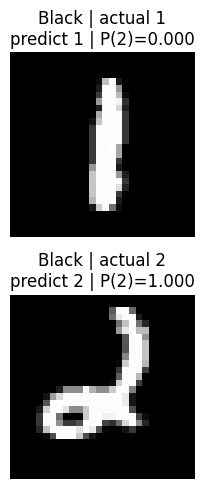

Correct 1-to-2 switches on black: 99.3%


In [3]:
baseline = fit_classifier()
black = probabilities(baseline, 0)
show_pair(PAIR, {0: black})
print(f"Correct 1-to-2 switches on black: {np.mean((black[:, 0] <= .5) & (black[:, 1] > .5)):.1%}")

## Training with correlated backgrounds

Horizontal stripes are associated with 1 and vertical stripes with 2. Train a separate CNN at each agreement level, keeping the seed, training order and number of epochs fixed. At test time, render both digits on both backgrounds.

In [4]:
scores = {}
for agreement in (.50, .75, .95, 1.00):
    model = fit_classifier(agreement)
    scores[agreement] = {bg: probabilities(model, bg) for bg in (1, 2)}
    print(f"Finished training at {agreement:.0%} agreement")

Finished training at 50% agreement
Finished training at 75% agreement
Finished training at 95% agreement
Finished training at 100% agreement


## Example predictions

Compare the same digit on two backgrounds and both digits on the same background. The displayed probability is the softmax output for digit 2.

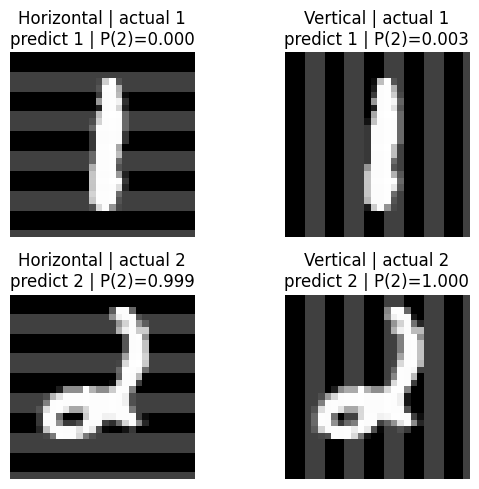

Horizontal: change in P(2) after replacing 1 with 2 = +0.999
Vertical: change in P(2) after replacing 1 with 2 = +0.996


In [5]:
example_pair = PAIR  # Try 1, 2, ... up to len(test)-1.
show_pair(example_pair, scores[.95])
for bg, p in scores[.95].items():
    delta = p[example_pair, 1] - p[example_pair, 0]
    print(f"{names[bg]}: change in P(2) after replacing 1 with 2 = {delta:+.3f}")

## Test-set results

A conflicting example is a 2 on horizontal stripes or a 1 on vertical stripes. Background following counts conflicting examples classified according to the stripes. The flip rate counts changes in predicted label after replacing only the background.

,aligned accuracy,background-following on conflicts,background-flip rate,correct digit switches on horizontal,correct digit switches on vertical,mean digit-swap change in P(2)
training agreement,,,,,,
0.50,0.995,0.004,0.000,0.990,0.991,0.985
0.75,0.997,0.007,0.003,0.989,0.990,0.982
0.95,0.999,0.017,0.016,0.979,0.985,0.965
1.00,1.000,0.874,0.874,0.253,0.000,0.150


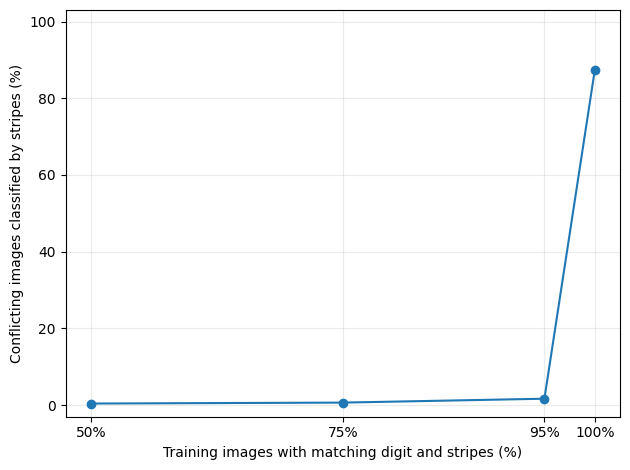

In [6]:
records = []
for agreement, by_bg in scores.items():
    h, v = by_bg[1], by_bg[2]
    h2, v2 = h > .5, v > .5
    records.append({
        "training agreement": agreement,
        "aligned accuracy": (np.mean(~h2[:, 0]) + np.mean(v2[:, 1])) / 2,
        "background-following on conflicts": (np.mean(~h2[:, 1]) + np.mean(v2[:, 0])) / 2,
        "background-flip rate": np.mean(h2 != v2),
        "correct digit switches on horizontal": np.mean(~h2[:, 0] & h2[:, 1]),
        "correct digit switches on vertical": np.mean(~v2[:, 0] & v2[:, 1]),
        "mean digit-swap change in P(2)": np.mean([h[:, 1]-h[:, 0], v[:, 1]-v[:, 0]])
    })
summary = pd.DataFrame(records).set_index("training agreement")
display(summary.round(3))
ax = (100 * summary["background-following on conflicts"]).plot(marker="o")
ax.set(xlabel="Training images with matching digit and stripes (%)",
       ylabel="Conflicting images classified by stripes (%)", ylim=(-3, 103),
       xticks=summary.index)
ax.set_xticklabels([f"{p:.0%}" for p in summary.index])
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()
summary.to_csv("mnist_swap_results.csv")

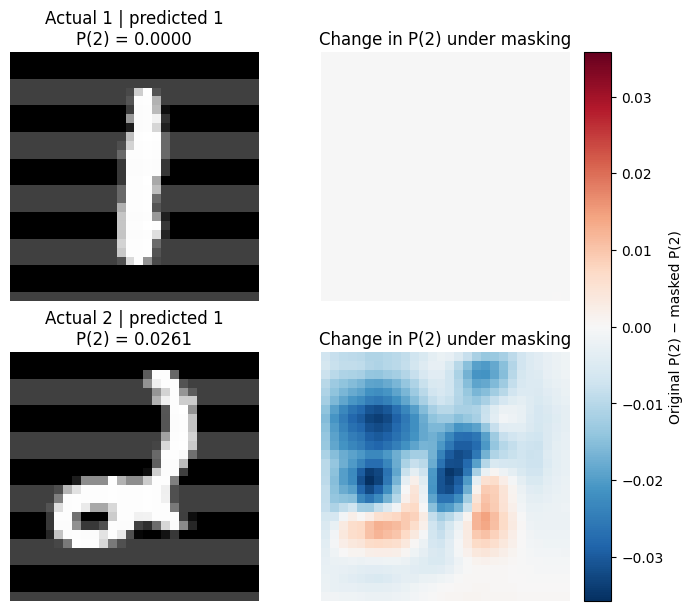

In [7]:
# Change this number to inspect another held-out pair.
pair_id = 0
bg_id = 1       # 0 = black, 1 = horizontal, 2 = vertical
target = 1      # Softmax index 1 corresponds to digit 2
patch_size = 5

def occlusion_map(image):
    original = float(model(image[None], training=False)[0, target])
    height, width = image.shape[:2]
    positions = [(r, c)
                 for r in range(height - patch_size + 1)
                 for c in range(width - patch_size + 1)]

    # Replace each patch with the same neutral gray.
    masked = np.repeat(image[None], len(positions), axis=0)
    for i, (r, c) in enumerate(positions):
        masked[i, r:r + patch_size, c:c + patch_size, :] = 0.125

    scores = model.predict(masked, batch_size=128, verbose=0)[:, target]
    total = np.zeros((height, width))
    count = np.zeros((height, width))
    for (r, c), drop in zip(positions, original - scores):
        region = np.s_[r:r + patch_size, c:c + patch_size]
        total[region] += drop
        count[region] += 1

    return original, total / count

images = [render(test[pair_id, row], bg_id) for row in (0, 1)]
results = [occlusion_map(image) for image in images]
limit = max(1e-6, max(np.abs(heat).max() for _, heat in results))

fig, axes = plt.subplots(2, 2, figsize=(7, 6), constrained_layout=True)
for row, (image, (p2, heat)) in enumerate(zip(images, results)):
    axes[row, 0].imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Actual {row + 1} | predicted {2 if p2 > .5 else 1}"
                           f"\nP(2) = {p2:.4f}")
    plot = axes[row, 1].imshow(heat, cmap="RdBu_r", vmin=-limit, vmax=limit)
    axes[row, 1].set_title("Change in P(2) under masking")
    for ax in axes[row]:
        ax.axis("off")

fig.colorbar(plot, ax=axes[:, 1], label="Original P(2) − masked P(2)")
plt.show()

In [8]:
ink_2 = test[pair_id, 1]  # Same handwritten 2 shown in the bottom row
for bg in (1, 2):
    image = render(ink_2, bg)
    p1, p2 = model(image[None], training=False).numpy()[0]
    print(f"{names[bg]:10s}  predicted {1 if p1 >= p2 else 2}  |  P(2) = {p2:.2%}")

Horizontal  predicted 1  |  P(2) = 2.61%
Vertical    predicted 2  |  P(2) = 99.97%


## Observations

The black-background model classified both digits correctly in 99.3% of test pairs. At 100% training agreement, the background swap changed 87.4% of predictions. At 95% agreement, the flip rate was 1.6%. These results use one training seed per condition.